# Croydon study area and descriptive grid comparison

Study reported pedestrian injury collisions in 2022–2025 within the ONS December 2024 Croydon footprint. This approved purposive case-study frame does not claim that the footprint equals each year's historical administrative area or represents London as a whole. No exposure-adjusted risk or causal effect is estimated.

**Status:** all eight code cells have saved counts 9–16 and no saved errors; both report-map exports were retained unchanged by the revised helper. The subsequent inference design is in [notebook 04](04_croydon_spatial_inference.ipynb); this notebook does not select it.

**Figure export:** enabled in the input cell for the new report figures, with identical PNGs retained and changed PNGs replaced after a complete save. `EXPORT_LEGACY_FIGURES = False` retains inline display of the original three-panel map without replacing its existing PNG. Inputs and validation artifacts remain unchanged. The exported maps have been visually inspected, while final PDF layout and complete attribution remain pending.

## Task 4: Study-area preparation and descriptive grid comparison

### 4.1 Scope, inputs and provenance

**Purpose:** run from `notebooks/` using the existing environment and supplied inputs, independently of earlier notebook kernels. Verify original boundary/guide provenance and the candidate hash against the saved validation run, then hash the audit and evidence inputs for this comparison. Expected totals below are reproduction checks from notebook 02, not newly calculated findings: [R01](../docs/references.md#r01), [R05](../docs/references.md#r05), [approved scope](../README.md#scope-and-status).


In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import NamedTemporaryFile
from importlib.metadata import version
import hashlib
import json
import os

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import CRS
from shapely import box
from IPython.display import display

DATA_DIR = Path(os.environ.get("COMP1890_DATA_DIR", "../data")).expanduser()
VALIDATION_DIR = Path(os.environ.get(
    "COMP1890_VALIDATION_DIR", str(DATA_DIR / "derived/spatial_validation_closure")
)).expanduser()
BOUNDARY_PATH = Path(os.environ.get(
    "COMP1890_BOUNDARY_PATH", str(DATA_DIR / "ons-lad-december-2024-uk-bfe.gpkg")
)).expanduser()
INPUTS = {
    "boundary": BOUNDARY_PATH,
    "guide": DATA_DIR / "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx",
    "candidates": DATA_DIR / "derived/pedestrian_collision_candidates.csv",
    "audit": VALIDATION_DIR / "collision_validation_audit.csv",
    "borough_evidence": VALIDATION_DIR / "borough_selection_evidence.csv",
    "validation_run": VALIDATION_DIR / "validation_run.json",
    "manifest": DATA_DIR / "download-manifest.json",
}
STUDY_CODE, STUDY_NAME = "E09000008", "Croydon"
YEARS = (2022, 2023, 2024, 2025)
EXPECTED_ANNUAL = {2022: 190, 2023: 200, 2024: 180, 2025: 222}
GRID_CRS = "EPSG:27700"
BOUNDARY_LAYER = "LAD_DEC_24_UK_BFE"
GRID_SIZES_M = (100, 250, 500)
GRID_ORIGIN_M = (0.0, 0.0)  # One British National Grid lattice origin for every size.
MAX_CANDIDATE_CELLS = 50000
# Image exports are optional; analysis inputs and dataset exports remain unchanged.
EXPORT_FIGURES = True
EXPORT_LEGACY_FIGURES = False  # Leave the existing three-panel export untouched.
FIGURE_DIR = Path(os.environ.get("COMP1890_FIGURE_DIR", "../evidence")).expanduser()


def save_report_figure(figure, filename):
    """Skip identical PNGs and replace changed images only after a complete save."""
    if not EXPORT_FIGURES:
        return
    output_path = FIGURE_DIR / filename
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
        png_bytes = buffer.getvalue()
    existed = output_path.exists()
    if existed and output_path.read_bytes() == png_bytes:
        print(f"Figure unchanged; kept existing PNG: {output_path}")
        return
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    temporary_path = None
    try:
        # A closed temporary file in the same directory supports atomic replacement.
        with NamedTemporaryFile(mode="wb", dir=FIGURE_DIR,
                                prefix=f".{output_path.name}.", suffix=".tmp",
                                delete=False) as handle:
            temporary_path = Path(handle.name)
            handle.write(png_bytes)
        os.replace(temporary_path, output_path)
    finally:
        if temporary_path is not None:
            temporary_path.unlink(missing_ok=True)
    action = "Updated" if existed else "Saved"
    print(f"{action} figure: {output_path}")

for path in INPUTS.values():
    if not path.is_file():
        raise FileNotFoundError(f"Required input missing: {path}. Check DATA_DIR and VALIDATION_DIR.")
manifest = json.loads(INPUTS["manifest"].read_text(encoding="utf-8"))
validation_run = json.loads(INPUTS["validation_run"].read_text(encoding="utf-8"))
if not isinstance(validation_run, dict) or not isinstance(validation_run.get("input_sha256"), dict):
    raise ValueError("Validation run metadata lacks input hashes; inspect notebook 02's export.")
entries = {entry["file"]: entry for entry in manifest["files"]}
input_hashes = {}
for label, path in INPUTS.items():
    with path.open("rb") as handle:
        digest = hashlib.file_digest(handle, "sha256").hexdigest()
    input_hashes[label] = digest
    if label in ("boundary", "guide", "candidates"):
        if validation_run["input_sha256"].get(label) != digest:
            raise ValueError(f"Input differs from the saved validation run: {label}.")
    if label in ("boundary", "guide"):
        entry = entries.get(path.name)
        if entry is None or entry["bytes"] != path.stat().st_size or entry["sha256"] != digest:
            raise ValueError(f"Original input differs from its manifest: {path.name}.")
versions = {name: version(name) for name in (
    "pandas", "numpy", "geopandas", "shapely", "pyproj", "pyogrio", "matplotlib")}
comparison_context = {
    "study_code": STUDY_CODE, "period": list(YEARS), "reference_geography": "December 2024 footprint",
    "input_sha256": input_hashes, "versions": versions, "grid_origin_m": GRID_ORIGIN_M,
    "grid_sizes_m": GRID_SIZES_M, "local_inference": "not_performed", "exports": "none",
}
display(pd.Series(versions, name="installed_version"))
display(pd.Series(input_hashes, name="sha256"))
print("Approved scope:", STUDY_NAME, YEARS, "within the December 2024 footprint.")
print("Hashes identify inputs; they do not verify artifact contents or positional accuracy.")


pandas         3.1.1
numpy          2.5.4
geopandas      1.2.0
shapely        2.2.0
pyproj         3.8.0
pyogrio       0.13.0
matplotlib    3.11.2
Name: installed_version, dtype: str

boundary            a421a026170391ade115e7424b8c4e06e682e0290978b8...
guide               51b08606ef3dad1ae5d4c8726241b022fc8e4bbdc910ef...
candidates          6599e3a378f930db908b225c5b554c624ee94159a5f419...
audit               0da6449bab739d5f3c970e95e819164cb716ca47559288...
borough_evidence    5ad9c445742f8b9309657f1592a9d9ad53c0380e01bfe0...
validation_run      d9966c7fc8f13000d54db2e79732e0ec31308ca31ef280...
manifest            444baba3f58e973b172059a75e48326f46cb4e5cf2e315...
Name: sha256, dtype: str

Approved scope: Croydon (2022, 2023, 2024, 2025) within the December 2024 footprint.
Hashes identify inputs; they do not verify artifact contents or positional accuracy.


**Findings:** boundary, guide and candidate hashes match the saved validation run, and the original boundary and guide also match the manifest. Package versions and all seven input hashes are displayed for this comparison; matching hashes do not establish positional accuracy or independently validate derived artifacts.

### 4.2 Footprint and selected collision records

**Purpose:** reconcile the audit's source fields with notebook 01's candidates, then select unique Croydon memberships within the approved years. Read the original reference polygon and verify that every selected grid-coordinate point is inside it, retaining recorded-code differences without corrections. Stop on unresolved recorded-Croydon cases or disagreement with the earlier selection totals; this is a selected-area check, not a repeat of London-wide validation.


In [2]:
source_fields = ["collision_index", "source_file_year", "collision_year", "date",
                 "location_easting_osgr", "location_northing_osgr", "local_authority_ons_district"]
audit = pd.read_csv(INPUTS["audit"], dtype=str, keep_default_na=False, encoding="utf-8-sig")
required = set(source_fields) | {"membership_status", "geometric_london_code"}
if not required.issubset(audit.columns):
    raise ValueError("Validation audit lacks required fields; inspect notebook 02's export.")
candidates = pd.read_csv(INPUTS["candidates"], usecols=source_fields,
                         dtype=str, keep_default_na=False, encoding="utf-8-sig")
for label, frame in (("audit", audit), ("candidates", candidates)):
    if frame["collision_index"].str.strip().eq("").any() or not frame["collision_index"].is_unique:
        raise ValueError(f"{label} requires nonblank, unique collision IDs.")
left = audit[source_fields].set_index("collision_index").sort_index()
right = candidates[source_fields].set_index("collision_index").sort_index()
if not left.equals(right):
    raise ValueError("Audit source fields do not reconcile with the candidate input.")
if not audit["source_file_year"].eq(audit["collision_year"]).all():
    raise ValueError("Audit source years and collision years differ.")
footprint_frame = gpd.read_file(INPUTS["boundary"], layer=BOUNDARY_LAYER,
    where=f"LAD24CD = '{STUDY_CODE}'", engine="pyogrio")
if (len(footprint_frame) != 1 or footprint_frame.crs != CRS.from_user_input(GRID_CRS)
        or footprint_frame.iloc[0]["LAD24NM"] != STUDY_NAME):
    raise ValueError("Expected one Croydon reference polygon in EPSG:27700.")
footprint = footprint_frame.geometry.iloc[0]
if (footprint is None or footprint.is_empty or not footprint.is_valid
        or footprint.geom_type not in ("Polygon", "MultiPolygon")):
    raise ValueError("The reference footprint must be a valid nonempty polygon; no repair applied.")
year_mask = audit["source_file_year"].isin([str(year) for year in YEARS])
recorded_here = year_mask & audit["local_authority_ons_district"].eq(STUDY_CODE)
if (recorded_here & audit["membership_status"].ne("unique_interior")).any():
    raise ValueError("Recorded-Croydon cases with unresolved membership require review.")
selected_mask = (year_mask & audit["membership_status"].eq("unique_interior")
                 & audit["geometric_london_code"].eq(STUDY_CODE))
study_records = audit.loc[selected_mask].copy()
if study_records.empty:
    raise ValueError("No collisions satisfy the approved footprint and period.")
study_records["easting"] = pd.to_numeric(study_records["location_easting_osgr"], errors="raise")
study_records["northing"] = pd.to_numeric(study_records["location_northing_osgr"], errors="raise")
if not np.isfinite(study_records[["easting", "northing"]].to_numpy(dtype=float)).all():
    raise ValueError("Selected grid coordinates must be finite.")
study_records["study_year"] = pd.to_numeric(study_records["source_file_year"], errors="raise").astype(int)
study_dates = pd.to_datetime(study_records["date"], format="%d/%m/%Y", errors="raise")
if not study_dates.dt.year.eq(study_records["study_year"]).all():
    raise ValueError("Selected dates disagree with their source years.")
study_points = gpd.GeoDataFrame(study_records.copy(),
    geometry=gpd.points_from_xy(study_records["easting"], study_records["northing"]), crs=GRID_CRS)
if not study_points.within(footprint).all():
    raise ValueError("Selected points do not all lie inside the reference footprint; inspect the audit.")
annual_counts = study_records.groupby("study_year").size().reindex(YEARS, fill_value=0)
if annual_counts.to_dict() != EXPECTED_ANNUAL:
    raise ValueError("Selected annual totals differ from the saved baseline; investigate before aggregation.")
borough_evidence = pd.read_csv(INPUTS["borough_evidence"], dtype=str, keep_default_na=False)
reference_row = borough_evidence.loc[borough_evidence["LAD24CD"].eq(STUDY_CODE)]
if len(reference_row) != 1 or int(reference_row.iloc[0]["geometric_total"]) != len(study_records):
    raise ValueError("Selected total does not reconcile with the borough evidence export.")
for year in YEARS:
    if int(reference_row.iloc[0][str(year)]) != int(annual_counts.loc[year]):
        raise ValueError("Annual totals do not reconcile with the borough evidence export.")
display(pd.Series({"selected_collisions": len(study_records),
    "unique_collision_ids": study_records["collision_index"].nunique(),
    "all_inside_reference_footprint": bool(study_points.within(footprint).all())}))
display(study_records[["collision_index", "source_file_year", "local_authority_ons_district",
                       "geometric_london_code", "membership_status"]].head())


selected_collisions                792
unique_collision_ids               792
all_inside_reference_footprint    True
dtype: object

,collision_index,source_file_year,local_authority_ons_district,geometric_london_code,membership_status
15,2022010352897,2022,E09000008,E09000008,unique_interior
17,2022010352922,2022,E09000008,E09000008,unique_interior
56,2022010353567,2022,E09000008,E09000008,unique_interior
110,2022010354330,2022,E09000008,E09000008,unique_interior
114,2022010354371,2022,E09000008,E09000008,unique_interior


**Findings:** the selection contains 792 unique collisions, all strictly inside the fixed Croydon footprint, with source fields reconciled against the candidate records. The total and annual counts match the saved borough evidence; recorded district differences are retained without correcting source values.

### 4.3 Annual totals, code differences and reporting limitations

**Purpose:** retain annual collision totals and incoming/outgoing district differences alongside the pooled dataset. DfT documents specification and severity-recording changes; including all injury severities avoids changes caused solely by serious/slight redistribution, but does not establish uniform reporting: [R19](../docs/references.md#r19). Reporting-basis assessment remains outstanding; annual movements alone do not justify a causal explanation or excluding a year.


In [3]:
incoming = selected_mask & audit["local_authority_ons_district"].ne(STUDY_CODE)
outgoing = recorded_here & audit["geometric_london_code"].ne(STUDY_CODE)
annual_summary = pd.DataFrame({"geometric_collision_count": annual_counts})
annual_summary.index.name = "year"
for label, mask in (("recorded_elsewhere_inside", incoming), ("recorded_here_outside", outgoing)):
    annual_summary[label] = [int((mask & audit["source_file_year"].eq(str(year))).sum()) for year in YEARS]
if int(annual_summary["geometric_collision_count"].sum()) != len(study_points):
    raise ValueError("Annual collision totals do not reconcile with the pooled selection.")
display(annual_summary)
reporting_limitations = {
    "all_injury_severities_included": True,
    "injury_reporting_basis_flags": "not_assessed_here; no inference about reporting-system changes",
    "annual_variation": "descriptive_only; no anomaly significance or causal explanation assigned",
    "source_coverage": "police-reported personal injury collisions; not all real-world events",
    "reference_geography": "fixed December 2024 footprint; historical boundary equality not established",
}
display(pd.Series(reporting_limitations, name="interpretation"))


,geometric_collision_count,recorded_elsewhere_inside,recorded_here_outside
year,,,
2022,190,1,0
2023,200,0,0
2024,180,0,0
2025,222,0,2


all_injury_severities_included                                                 True
injury_reporting_basis_flags      not_assessed_here; no inference about reportin...
annual_variation                  descriptive_only; no anomaly significance or c...
source_coverage                   police-reported personal injury collisions; no...
reference_geography               fixed December 2024 footprint; historical boun...
Name: interpretation, dtype: object

**Findings:** annual collision counts are 190, 200, 180 and 222 for 2022–2025. One event recorded elsewhere lies inside the footprint in 2022, while two recorded-Croydon events lie outside it in 2025. These descriptive counts do not explain annual variation or establish uniform reporting; reporting-basis flags remain unassessed here.

### 4.4 Grid rules fixed before comparison

**Purpose:** compare 100 m, 250 m and 500 m cells on one EPSG:27700 lattice anchored at (0, 0), retaining every positive-area footprint intersection and every zero-count cell. Assign points by half-open full-square intervals, record clipped area fractions and verify event totals and footprint-area coverage without nearest-cell corrections. Compare sparsity, count distribution, spatial detail and edge-cell burden before choosing a grid; no significance results, automatic score or minimum-count threshold determine the choice.


In [4]:
def build_count_grid(study_points, footprint, size_m, origin=(0.0, 0.0), max_cells=50000):
    """Count unique interior events on a half-open lattice; retain positive-area clips."""
    if not np.isfinite(size_m) or size_m <= 0:
        raise ValueError("Grid size must be finite and positive.")
    if len(origin) != 2 or not np.isfinite(origin).all():
        raise ValueError("Grid origin requires two finite coordinates.")
    if (footprint.is_empty or not footprint.is_valid
            or footprint.geom_type not in ("Polygon", "MultiPolygon")):
        raise ValueError("A valid nonempty polygon footprint is required.")
    if study_points.crs != CRS.from_user_input("EPSG:27700"):
        raise ValueError("Grid counting requires points in EPSG:27700.")
    if (study_points["collision_index"].isna().any()
            or study_points["collision_index"].astype(str).str.strip().eq("").any()
            or not study_points["collision_index"].is_unique):
        raise ValueError("Each collision must have a nonblank unique ID.")
    xy = np.column_stack((study_points.geometry.x, study_points.geometry.y))
    if not np.isfinite(xy).all() or not study_points.within(footprint).all():
        raise ValueError("Every event must be finite and strictly inside the footprint.")
    x0, y0 = origin
    xmin, ymin, xmax, ymax = footprint.bounds
    col_min, col_max = int(np.floor((xmin - x0) / size_m)), int(np.floor((xmax - x0) / size_m))
    row_min, row_max = int(np.floor((ymin - y0) / size_m)), int(np.floor((ymax - y0) / size_m))
    candidate_count = (col_max - col_min + 1) * (row_max - row_min + 1)
    if candidate_count > max_cells:
        raise ValueError(f"Grid needs {candidate_count:,} candidate cells; review size and max_cells before proceeding.")
    cols, rows = np.meshgrid(np.arange(col_min, col_max + 1), np.arange(row_min, row_max + 1))
    cols, rows = cols.ravel(), rows.ravel()
    x, y = x0 + cols * size_m, y0 + rows * size_m
    squares = gpd.GeoDataFrame({"grid_col": cols, "grid_row": rows},
        geometry=box(x, y, x + size_m, y + size_m), crs=study_points.crs)
    clipped = squares.geometry.intersection(footprint)
    positive_area = clipped.area.gt(0)
    grid = squares.loc[positive_area].copy()
    grid.geometry = clipped.loc[positive_area]
    if grid.empty or not grid.geometry.is_valid.all():
        raise ValueError("Clipped grid is empty or invalid; no automatic repair applied.")
    grid["area_m2"] = grid.geometry.area
    grid["area_fraction"] = grid["area_m2"] / float(size_m ** 2)
    # Dimensionless floating-point allowance for classifying full squares, not a spatial cutoff.
    fraction_tolerance = 1e-9
    if not grid["area_fraction"].between(0, 1 + fraction_tolerance, inclusive="right").all():
        raise ValueError("Cell area fractions are outside the expected range.")
    grid["partial_cell"] = grid["area_fraction"].lt(1 - fraction_tolerance)
    if not np.isclose(grid["area_m2"].sum(), footprint.area, rtol=1e-9, atol=1e-4):
        raise ValueError("Clipped cell areas do not reconcile with footprint area.")
    grid = grid.set_index(["grid_col", "grid_row"]).sort_index()
    assigned = pd.DataFrame({"collision_index": study_points["collision_index"].to_numpy(),
        "grid_col": np.floor((xy[:, 0] - x0) / size_m).astype(np.int64),
        "grid_row": np.floor((xy[:, 1] - y0) / size_m).astype(np.int64)})
    counts = assigned.groupby(["grid_col", "grid_row"]).size()
    if not counts.index.isin(grid.index).all():
        raise ValueError("An event was assigned to a cell without positive footprint area.")
    grid["collision_count"] = counts.reindex(grid.index, fill_value=0).astype(int)
    if grid["collision_count"].sum() != len(study_points):
        raise ValueError("Cell counts do not reconcile with selected collision totals.")
    grid = grid.reset_index()
    grid["cell_id"] = [f"{size_m:g}m_{col}_{row}" for col, row in zip(
        grid["grid_col"], grid["grid_row"], strict=True)]
    return grid, assigned


def summarise_grid(grid, size_m):
    """Describe all retained cells, with occupied-cell statistics explicitly labelled."""
    counts = grid["collision_count"]
    occupied = counts.loc[counts.gt(0)]
    partial = grid["partial_cell"]
    total = int(counts.sum())
    return {"cell_size_m": size_m, "retained_cells": len(grid),
        "zero_count_cells": int(counts.eq(0).sum()), "zero_count_pct": 100 * counts.eq(0).mean(),
        "occupied_cells": len(occupied), "mean_count_all_cells": counts.mean(),
        "median_count_all_cells": counts.median(), "p95_count_all_cells": counts.quantile(0.95),
        "median_count_occupied_cells": occupied.median() if len(occupied) else np.nan,
        "maximum_count": int(counts.max()), "partial_cells": int(partial.sum()),
        "partial_cell_pct": 100 * partial.mean(), "minimum_area_fraction": grid["area_fraction"].min(),
        "events_in_partial_cells": int(counts.loc[partial].sum()),
        "event_pct_in_partial_cells": 100 * counts.loc[partial].sum() / total if total else np.nan,
        "total_collisions": total}


**Findings:** the function stops if assigned collision totals or clipped-area coverage do not reconcile. Zero-count and positive-area partial cells remain included; clipped area describes geometric support rather than pedestrian exposure.

### 4.5 Descriptive grid comparison

**Purpose:** build the three candidate grids under the same inclusion and assignment rules, retaining assignments for inspection in memory. Report zero counts, occupied-cell statistics and partial-cell burden with explicit denominators, checking that each grid counts every selected collision once. Partial cells remain included; their unequal areas must be considered before local inference, and no grid is selected automatically.


In [5]:
grids, assignments, comparison_rows = {}, {}, []
for size_m in GRID_SIZES_M:
    grid, assigned = build_count_grid(study_points, footprint, size_m,
        origin=GRID_ORIGIN_M, max_cells=MAX_CANDIDATE_CELLS)
    grids[size_m], assignments[size_m] = grid, assigned
    comparison_rows.append(summarise_grid(grid, size_m))
grid_comparison = pd.DataFrame(comparison_rows).set_index("cell_size_m")
if not grid_comparison["total_collisions"].eq(len(study_points)).all():
    raise ValueError("Candidate grids count different event populations.")
display(grid_comparison.T)
print("Origin:", GRID_ORIGIN_M, "in", GRID_CRS)
print("Cell rule: positive-area footprint intersections, including zeros; no centroid or area-fraction exclusions.")
print("Assignment: floor-based half-open squares; no coordinate rounding or nearest-cell allocation.")
print("No grid, neighbourhood, statistic or sensitivity setting has been selected.")


cell_size_m,100,250,500
retained_cells,9006.000000,1520.000000,415.000000
zero_count_cells,8472.000000,1169.000000,230.000000
zero_count_pct,94.070620,76.907895,55.421687
occupied_cells,534.000000,351.000000,185.000000
mean_count_all_cells,0.087941,0.521053,1.908434
median_count_all_cells,0.000000,0.000000,0.000000
p95_count_all_cells,1.000000,3.000000,9.000000
median_count_occupied_cells,1.000000,1.000000,3.000000
maximum_count,7.000000,17.000000,28.000000
partial_cells,710.000000,274.000000,128.000000


Origin: (0.0, 0.0) in EPSG:27700
Cell rule: positive-area footprint intersections, including zeros; no centroid or area-fraction exclusions.
Assignment: floor-based half-open squares; no coordinate rounding or nearest-cell allocation.
No grid, neighbourhood, statistic or sensitivity setting has been selected.


**Findings:** the 100 m, 250 m and 500 m grids retain 9,006, 1,520 and 415 cells, with zero-count shares of 94.1%, 76.9% and 55.4%, respectively. Partial cells account for 7.9%, 18.0% and 30.8% of cells and contain 20, 41 and 74 collisions. Coarser grids reduce sparsity while increasing boundary-cell involvement; grid selection is not performed in this descriptive notebook; notebook 04 uses the subsequent approved 500 m main and 250 m sensitivity settings.

### 4.6 Spatial detail and count distributions

**Purpose:** map the three clipped grids with one shared count colour scale and compare the percentage of cells in common count bands. Larger cells cover more area, so differences in raw counts are partly structural rather than evidence of greater risk. Use the maps with the table to explain spatial detail, sparsity and edge effects alongside notebook 04's subsequent main and sensitivity settings.


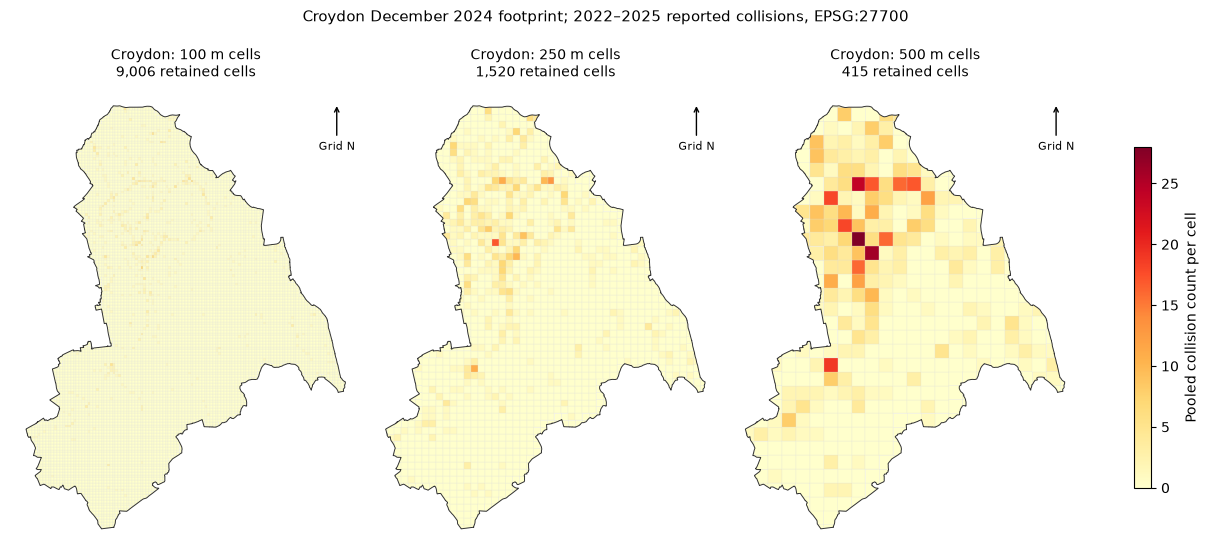

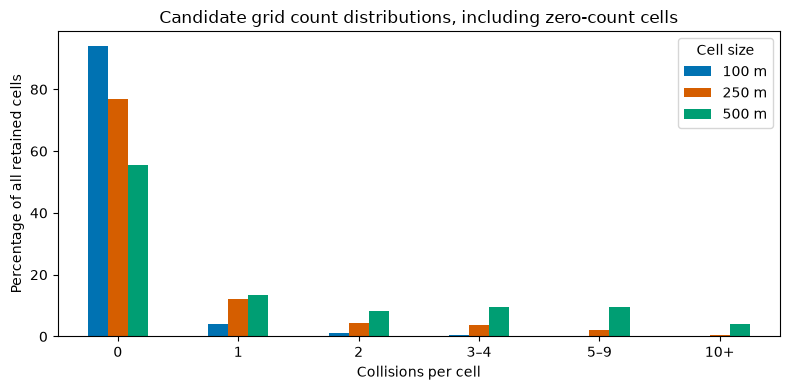

Sources: DfT collision/casualty data; ONS December 2024 BFE reference footprint (R01/R05/R06).
These are descriptive count maps, not statistical hotspot or exposure-adjusted risk maps.
Product-specific ONS/OS attribution and final report-layout review remain required before report reuse.


In [6]:
maximum = max(int(grid["collision_count"].max()) for grid in grids.values())
fig, axes = plt.subplots(1, len(GRID_SIZES_M), figsize=(12, 6), layout="constrained")
for ax, size_m in zip(axes, GRID_SIZES_M, strict=True):
    grid = grids[size_m]
    grid.plot(ax=ax, column="collision_count", cmap="YlOrRd", vmin=0, vmax=max(maximum, 1),
              edgecolor="#dddddd", linewidth=0.15)
    footprint_frame.boundary.plot(ax=ax, color="#333333", linewidth=0.7)
    ax.set_title(f"Croydon: {size_m} m cells\n{len(grid):,} retained cells", fontsize=10)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.annotate("Grid N", xy=(0.93, 0.96), xytext=(0.93, 0.86), xycoords="axes fraction",
                ha="center", fontsize=8, arrowprops={"arrowstyle": "->"})
colourbar = plt.cm.ScalarMappable(norm=plt.Normalize(0, max(maximum, 1)), cmap="YlOrRd")
fig.colorbar(colourbar, ax=list(axes), shrink=0.6, label="Pooled collision count per cell")
fig.suptitle("Croydon December 2024 footprint; 2022–2025 reported collisions, EPSG:27700", fontsize=11)
if EXPORT_LEGACY_FIGURES:
    save_report_figure(fig, "croydon_grid_comparison_100m_250m_500m.png")
plt.show()
bands = ["0", "1", "2", "3–4", "5–9", "10+"]
distribution = pd.DataFrame(index=bands)
for size_m, grid in grids.items():
    counts = grid["collision_count"]
    groups = pd.cut(counts, bins=[-1, 0, 1, 2, 4, 9, np.inf], labels=bands)
    distribution[f"{size_m} m"] = groups.value_counts(sort=False).reindex(bands, fill_value=0) / len(grid) * 100
ax = distribution.plot.bar(figsize=(8, 4), color=["#0072B2", "#D55E00", "#009E73"], rot=0)
ax.set(xlabel="Collisions per cell", ylabel="Percentage of all retained cells",
       title="Candidate grid count distributions, including zero-count cells")
ax.legend(title="Cell size")
plt.tight_layout()
plt.show()
print("Sources: DfT collision/casualty data; ONS December 2024 BFE reference footprint (R01/R05/R06).")
print("These are descriptive count maps, not statistical hotspot or exposure-adjusted risk maps.")
print("Product-specific ONS/OS attribution and final report-layout review remain required before report reuse.")


**Findings:** the maps show stronger count shading in the northern portion of the footprint, particularly at 500 m, while the distribution chart confirms the large zero-count share at every size. The shared count scale makes fine-grid differences less visible, and larger counts in larger cells partly reflect aggregation. These are descriptive concentrations, not significant hotspots or risk estimates; the subsequent approved inference design and saved results are in [notebook 04](04_croydon_spatial_inference.ipynb).

### 4.7 Report map: collision locations and London context

**Purpose:** show the selected recorded locations and locate Croydon within London using the same boundary input. Retain overlapping locations without jittering or inferring road alignment; include a grid-north arrow, distance bar and sources, while marking the unresolved attribution year as draft.


Figure unchanged; kept existing PNG: ../evidence/croydon_collision_locations_context.png


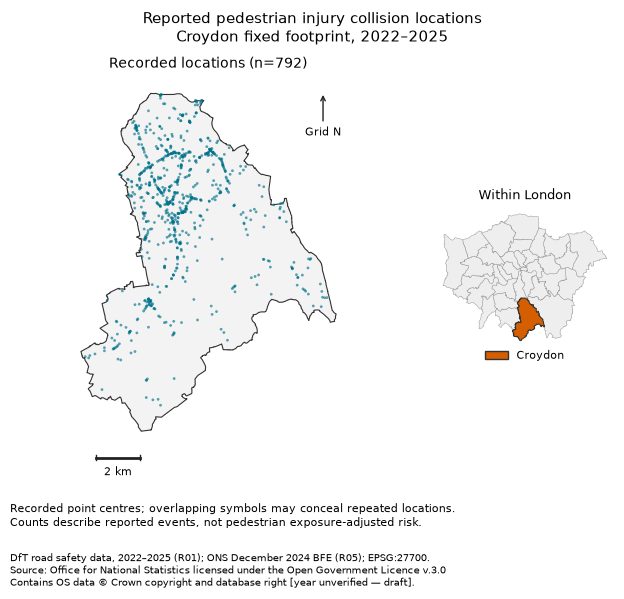

In [7]:
def add_report_map_details(ax, bounds, scale_m=2000):
    """Add a grid-north arrow and a metre-based bar below the mapped footprint."""
    xmin, ymin, xmax, ymax = bounds
    width, height = xmax - xmin, ymax - ymin
    ax.set(xlim=(xmin - 0.05 * width, xmax + 0.05 * width),
           ylim=(ymin - 0.14 * height, ymax + 0.05 * height), aspect="equal")
    ax.set_axis_off()
    start_x, bar_y = xmin + 0.06 * width, ymin - 0.08 * height
    ax.plot([start_x, start_x + scale_m], [bar_y, bar_y], color="#222222", linewidth=2)
    for end_x in (start_x, start_x + scale_m):
        ax.plot([end_x, end_x], [bar_y - 0.008 * height, bar_y + 0.008 * height],
                color="#222222", linewidth=1)
    ax.text(start_x + scale_m / 2, bar_y - 0.025 * height, f"{scale_m / 1000:g} km",
            ha="center", va="top", fontsize=8)
    ax.annotate("Grid N", xy=(0.91, 0.96), xytext=(0.91, 0.86),
                xycoords="axes fraction", ha="center", va="center", fontsize=8,
                arrowprops={"arrowstyle": "->", "color": "#222222"})


def add_report_sources(figure):
    """Keep sources and the unresolved product-specific copyright year visible."""
    figure.text(0.02, 0.015,
        "DfT road safety data, 2022–2025 (R01); ONS December 2024 BFE (R05); EPSG:27700.\n"
        "Source: Office for National Statistics licensed under the Open Government Licence v.3.0\n"
        "Contains OS data © Crown copyright and database right [year unverified — draft].",
        ha="left", va="bottom", fontsize=7)

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Use only the 33 London districts from the same verified boundary input.
london_locator = gpd.read_file(INPUTS["boundary"], layer=BOUNDARY_LAYER,
    where="LAD24CD LIKE 'E090000%'", engine="pyogrio")
expected_london_codes = {f"E090000{i:02d}" for i in range(1, 34)}
if (len(london_locator) != 33 or set(london_locator["LAD24CD"]) != expected_london_codes
        or not london_locator["LAD24CD"].is_unique
        or london_locator.crs != CRS.from_user_input(GRID_CRS)
        or london_locator.geometry.isna().any() or london_locator.geometry.is_empty.any()
        or not london_locator.geometry.is_valid.all()):
    raise ValueError("The locator requires 33 valid, unique London districts in EPSG:27700.")
locator_croydon = london_locator.loc[london_locator["LAD24CD"].eq(STUDY_CODE)]
if not locator_croydon.geometry.iloc[0].equals(footprint):
    raise ValueError("The locator Croydon geometry differs from the analysis footprint.")

fig, (point_ax, locator_ax) = plt.subplots(1, 2, figsize=(6.3, 6.0),
    gridspec_kw={"width_ratios": [2.2, 1]})
fig.subplots_adjust(left=0.02, right=0.98, top=0.87, bottom=0.20, wspace=0.10)
footprint_frame.plot(ax=point_ax, facecolor="#f3f3f3", edgecolor="#333333", linewidth=0.8)
study_points.plot(ax=point_ax, color="#00728a", markersize=4, alpha=0.65, edgecolor="none")
add_report_map_details(point_ax, footprint.bounds)
point_ax.set_title(f"Recorded locations (n={len(study_points):,})", fontsize=10)
london_locator.plot(ax=locator_ax, facecolor="#eeeeee", edgecolor="#999999", linewidth=0.35)
locator_croydon.plot(ax=locator_ax, facecolor="#d55e00", edgecolor="#333333", linewidth=0.7)
locator_ax.set_aspect("equal"); locator_ax.set_axis_off()
locator_ax.set_title("Within London", fontsize=9)
locator_ax.legend(handles=[Patch(facecolor="#d55e00", edgecolor="#333333", label="Croydon")],
                  loc="lower center", bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=8)
fig.suptitle("Reported pedestrian injury collision locations\nCroydon fixed footprint, 2022–2025", fontsize=11)
fig.text(0.02, 0.12, "Recorded point centres; overlapping symbols may conceal repeated locations.\n"
         "Counts describe reported events, not pedestrian exposure-adjusted risk.", fontsize=8)
add_report_sources(fig)
save_report_figure(fig, "croydon_collision_locations_context.png")
plt.show()


**Findings:** the map displays the 792 selected recorded locations, with a denser northern pattern and Croydon highlighted within London. The saved export message reports that the PNG is byte-identical and was retained; symbols can overlap, and no independent positional accuracy, road alignment or risk claim is made. Final PDF layout and the attribution year remain pending.


### 4.8 Report map: 250 m and 500 m count grids

**Purpose:** reuse the existing grids with shared count classes and dashed outlines for partial cells, keeping zero-count cells and the original three-panel figure. This is a presentation comparison of raw counts, not a density or significance map; it does not change assignment or inference settings.


Figure unchanged; kept existing PNG: ../evidence/croydon_grid_comparison_250m_500m.png


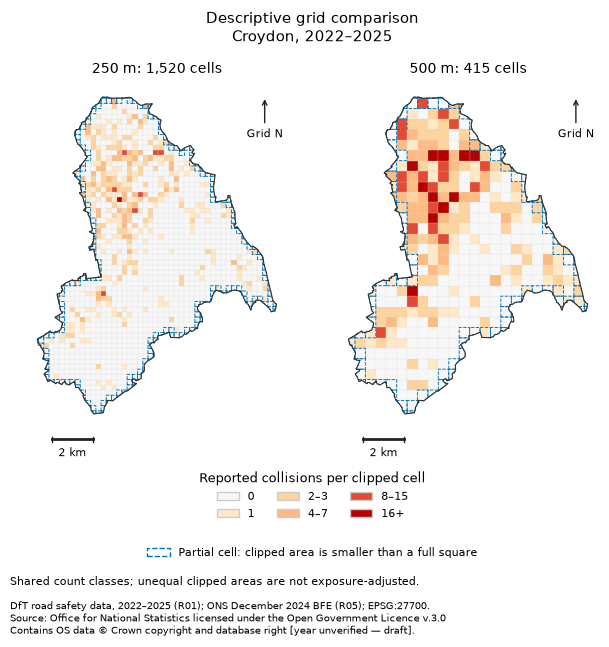

In [8]:
from matplotlib.patches import Patch

REPORT_GRID_SIZES_M = (250, 500)
count_labels = ("0", "1", "2–3", "4–7", "8–15", "16+")
count_colours = ("#f7f7f7", "#fee8c8", "#fdd49e", "#fdbb84", "#e34a33", "#b30000")
palette = dict(zip(count_labels, count_colours, strict=True))
fig, axes = plt.subplots(1, 2, figsize=(6.3, 6.5))
fig.subplots_adjust(left=0.02, right=0.98, top=0.87, bottom=0.29, wspace=0.06)
for ax, size_m in zip(axes, REPORT_GRID_SIZES_M, strict=True):
    grid = grids[size_m]
    groups = pd.cut(grid["collision_count"], bins=[-1, 0, 1, 3, 7, 15, np.inf], labels=count_labels)
    if groups.isna().any():
        raise ValueError("Report count classes must cover every retained cell.")
    colours = [palette[label] for label in groups]
    grid.plot(ax=ax, color=colours, edgecolor="#dddddd", linewidth=0.15)
    partial = grid.loc[grid["partial_cell"]]
    if not partial.empty:
        partial.boundary.plot(ax=ax, color="#0072b2", linestyle="--", linewidth=0.65)
    footprint_frame.boundary.plot(ax=ax, color="#333333", linewidth=0.8)
    add_report_map_details(ax, footprint.bounds)
    ax.set_title(f"{size_m} m: {len(grid):,} cells", fontsize=10)
handles = [Patch(facecolor=colour, edgecolor="#cccccc", label=label)
           for label, colour in palette.items()]
fig.legend(handles=handles, title="Reported collisions per clipped cell", loc="lower center",
           bbox_to_anchor=(0.5, 0.18), ncol=3, fontsize=8, title_fontsize=9, frameon=False)
fig.legend(handles=[Patch(facecolor="none", edgecolor="#0072b2", linestyle="--",
                         label="Partial cell: clipped area is smaller than a full square")],
           loc="lower center", bbox_to_anchor=(0.5, 0.12), fontsize=8, frameon=False)
fig.suptitle("Descriptive grid comparison\nCroydon, 2022–2025", fontsize=11)
fig.text(0.02, 0.095, "Shared count classes; unequal clipped areas are not exposure-adjusted.", fontsize=8)
add_report_sources(fig)
save_report_figure(fig, "croydon_grid_comparison_250m_500m.png")
plt.show()


**Findings:** both maps show the same broad northern concentration, with finer spatial detail at 250 m and more aggregation at 500 m. Shared count classes, dashed partial-cell outlines and scale bars are visible, and the saved export message reports an unchanged PNG. Raw counts remain sensitive to cell size and clipped area; final PDF layout and attribution remain pending.
